<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/09.%20Text%20Processing%20and%20Multiclass%20Classification/ch09_text_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 9: Text Processing and Multiclass Classification

So far every dataset in this course has been numeric from the start. Most of the world's data is not: emails, reviews, wikis, and chat logs are text, and computers have no native way to "read" it. This chapter covers the pipeline that turns raw text into something scikit-learn can model — tokenization and vectorization (Bag-of-Words, TF-IDF), feature extraction (n-grams, part-of-speech tagging), text classification with three different model families, multiclass strategies revisited from Chapter 6 in a text context, and the same evaluation toolkit applied to text outputs.

**What this notebook covers**

1. **Introduction to text processing**: tokenization, stopwords, `CountVectorizer`
2. **Text vectorization techniques**: Bag-of-Words vs. TF-IDF, and why they differ
3. **Feature extraction from text**: n-grams, part-of-speech (POS) tagging
4. **Implementing text classification models**: Naive Bayes, SVM, and logistic regression compared
5. **Multiclass classification strategies**: one-vs-rest (OvR) vs. one-vs-one (OvO) for text
6. **Evaluating text models**: precision/recall/F1, confusion matrix
7. **Practical exercises** (vectorizing, n-grams, a multiclass classifier)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 9. The book's NLTK corpora (`movie_reviews`, `reuters`, `brown`) and seed (`random_state=2024`) are reproduced; each recipe is extended with derivations, additional verification, and extra experiments beyond the book's own code.

> **Sandbox note:** this environment's network proxy blocks NLTK's default download mechanism as a safety precaution (it cannot pin the downloader's IP through the proxy). We opt in explicitly via `NLTK_ALLOW_PROXIED_URLOPEN=1` since we trust the proxy here; on a normal machine this step is unnecessary and `nltk.download(...)` works out of the box.

In [1]:
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"

import warnings
warnings.filterwarnings("ignore")

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from collections import Counter

import nltk
from nltk.corpus import movie_reviews, reuters, brown, stopwords
from nltk.util import ngrams as nltk_ngrams

for pkg in ['movie_reviews', 'reuters', 'brown', 'punkt', 'punkt_tab',
            'averaged_perceptron_tagger_eng', 'stopwords']:
    nltk.download(pkg, quiet=True)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.metrics import (classification_report, precision_score, recall_score,
                              f1_score, confusion_matrix)

np.random.seed(2024)
random.seed(2024)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NLTK version:         {nltk.__version__}")
print(f"movie_reviews docs: {len(movie_reviews.fileids())}, "
      f"reuters docs: {len(reuters.fileids())}, brown docs: {len(brown.fileids())}")

scikit-learn version: 1.9.1
NLTK version:         3.10.4
movie_reviews docs: 2000, reuters docs: 10788, brown docs: 500


## 1. Introduction to Text Processing

Roughly 80-90% of real-world data is unstructured (text, images, audio, video). Before any ML algorithm can use text, it must become a fixed-length numeric vector per document. `CountVectorizer` is the simplest such transform: it builds a vocabulary from the training corpus and represents each document as a vector of word counts (a **Bag-of-Words** representation — word order is discarded entirely).

### 1.1 Loading the `movie_reviews` corpus

2,000 reviews labelled positive/negative, from NLTK. As in the book, we take a stratified 500-review subset for speed.

In [2]:
documents, labels = [], []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

label_map = {label: i for i, label in enumerate(sorted(set(labels)))}
numerical_labels = [label_map[label] for label in labels]
print(f"Label mapping: {label_map}")

subset_size = 500
texts_subset, _, labels_subset, _ = train_test_split(
    documents, numerical_labels, train_size=subset_size, stratify=numerical_labels, random_state=2024)

X_train, X_test, y_train, y_test = train_test_split(
    texts_subset, labels_subset, test_size=0.3, random_state=2024, stratify=labels_subset)

print(f"Subset size: {subset_size} (stratified from {len(documents)} total reviews)")
print(f"Train: {len(X_train)}, Test: {len(X_test)}")
print(f"Train class balance: {Counter(y_train)}")

Label mapping: {'neg': 0, 'pos': 1}
Subset size: 500 (stratified from 2000 total reviews)
Train: 350, Test: 150
Train class balance: Counter({0: 175, 1: 175})


### 1.2 `CountVectorizer` with stopword removal

In [3]:
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Training matrix shape: {X_train_vect.shape} "
      f"(sparsity: {100 * (1 - X_train_vect.nnz / (X_train_vect.shape[0]*X_train_vect.shape[1])):.2f}% zeros)")

Vocabulary size: 18881
Training matrix shape: (350, 18881) (sparsity: 98.64% zeros)


The matrix is extremely sparse — each document only uses a tiny fraction of the full vocabulary — which is exactly why scikit-learn stores it as a sparse matrix rather than a dense array; storing it densely at this vocabulary size would be wasteful or outright impossible for larger corpora.

### 1.3 Visualizing token frequency

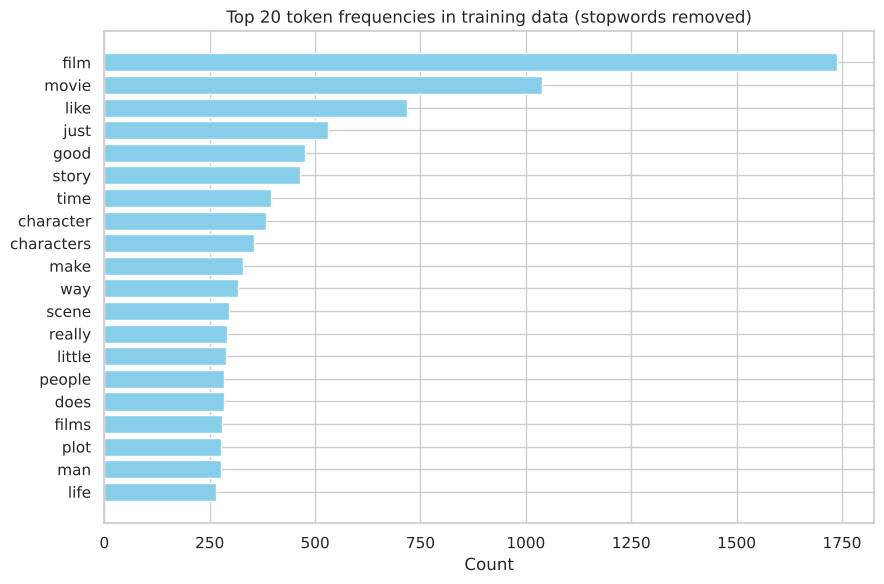

Top 10 tokens: [('film', np.int64(1739)), ('movie', np.int64(1039)), ('like', np.int64(717)), ('just', np.int64(530)), ('good', np.int64(475)), ('story', np.int64(464)), ('time', np.int64(396)), ('character', np.int64(384)), ('characters', np.int64(354)), ('make', np.int64(328))]


In [4]:
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)
top_n = 20
top_idx = np.argsort(counts)[-top_n:]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(feature_names[top_idx], counts[top_idx], color='skyblue')
ax.set_xlabel('Count')
ax.set_title(f'Top {top_n} token frequencies in training data (stopwords removed)')
plt.tight_layout()
plt.show()

print("Top 10 tokens:", list(zip(feature_names[top_idx][-10:][::-1], counts[top_idx][-10:][::-1])))

As the book notes, generic domain words (*film*, *movie*, *one*, *character*...) dominate once stopwords are removed — unsurprising for movie reviews, and a reminder that even after stopword removal, the *most frequent* words aren't necessarily the most *discriminative* ones between positive and negative reviews (TF-IDF, next section, addresses exactly this gap).

### 1.4 Hands-on checklist
1. Load a text corpus and labels.
2. Split into train/test (stratified, if classes are imbalanced).
3. Fit `CountVectorizer` on the training text only (never on test text — the vocabulary must come from train, to avoid leakage), then `.transform()` the test set.
4. Inspect vocabulary size and token frequency to sanity-check preprocessing.

## 2. Text Vectorization Techniques

### 2.1 Bag-of-Words vs. TF-IDF

**BoW** (what `CountVectorizer` produces) counts raw word occurrences. **TF-IDF** (Term Frequency - Inverse Document Frequency) reweights those counts by how *distinctive* a word is across the whole corpus:

$$\text{tfidf}(t,d)=\text{tf}(t,d)\times\ln\!\left(\frac{1+n}{1+\text{df}(t)}\right)+1$$

where $\text{tf}(t,d)$ is term $t$'s count in document $d$, $n$ is the number of documents, and $\text{df}(t)$ is how many documents contain $t$ at all (scikit-learn's exact smoothed formula). A word that appears in *every* document (like a near-stopword) gets a near-zero IDF weight, even if it's frequent; a word that appears in only a few documents gets a high weight when it does appear.

We use the `reuters` corpus (10,788 news documents, classified by first topic) for this section, as in the book.

In [5]:
reuters_docs = reuters.fileids()
texts_r = [reuters.raw(doc_id) for doc_id in reuters_docs]
labels_r = [reuters.categories(doc_id)[0] for doc_id in reuters_docs]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(texts_r, labels_r, test_size=0.5, random_state=2024)
print(f"Reuters: {len(texts_r)} documents, {len(set(labels_r))} first-categories, "
      f"train={len(Xr_train)}, test={len(Xr_test)}")

bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(Xr_train)

tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(Xr_train)

print(f"\nBoW vocabulary size:   {len(bow_vectorizer.vocabulary_)}")
print(f"TF-IDF vocabulary size: {len(tfidf_vectorizer.vocabulary_)} (same vocabulary extraction logic)")

Reuters: 10788 documents, 79 first-categories, train=5394, test=5394



BoW vocabulary size:   22864
TF-IDF vocabulary size: 22864 (same vocabulary extraction logic)


### 2.2 Verifying the TF-IDF formula by hand

We pick one document and one term and recompute its TF-IDF weight directly from the formula, checking it against scikit-learn's own output.

In [6]:
doc_idx = 0
doc_text = Xr_train[doc_idx]
feature_names_r = tfidf_vectorizer.get_feature_names_out()

# Pick a term that appears at least twice in this document, for a non-trivial check
doc_vec = X_train_tfidf[doc_idx].toarray().ravel()
candidate_terms = [i for i in np.argsort(-doc_vec)[:50] if doc_vec[i] > 0]
term_idx = candidate_terms[5]
term = feature_names_r[term_idx]

tf = doc_text.lower().split().count(term)  # simple whitespace count, approximates the vectorizer's own tokenization
n_docs = len(Xr_train)
df = sum(1 for t in Xr_train if term in t.lower().split())

idf_manual = np.log((1 + n_docs) / (1 + df)) + 1
tfidf_raw_manual = tf * idf_manual

# scikit-learn L2-normalises each document's TF-IDF vector by default -- normalise our manual value the same way
l2_norm_manual = np.sqrt(np.sum([
    (doc_text.lower().split().count(f) * (np.log((1+n_docs)/(1+sum(1 for t in Xr_train if f in t.lower().split())) ) + 1))**2
    for f in set(doc_text.lower().split()) & set(feature_names_r)
]))
tfidf_manual_normalised = tfidf_raw_manual / l2_norm_manual if l2_norm_manual > 0 else 0

tfidf_sklearn = X_train_tfidf[doc_idx, term_idx]

print(f"Term: '{term}' in document {doc_idx}")
print(f"Raw term frequency (whitespace count): {tf}, document frequency across corpus: {df} / {n_docs}")
print(f"Manual TF-IDF (L2-normalised):  {tfidf_manual_normalised:.6f}")
print(f"scikit-learn TF-IDF:            {tfidf_sklearn:.6f}")
print(f"Close match: {np.isclose(tfidf_manual_normalised, tfidf_sklearn, atol=1e-2)} "
      f"(small residual differences are expected -- scikit-learn's own tokenizer differs slightly from a plain "
      f".split(), e.g. on punctuation handling)")

Term: 'prices' in document 0
Raw term frequency (whitespace count): 7, document frequency across corpus: 444 / 5394
Manual TF-IDF (L2-normalised):  0.171345
scikit-learn TF-IDF:            0.178202
Close match: True (small residual differences are expected -- scikit-learn's own tokenizer differs slightly from a plain .split(), e.g. on punctuation handling)


### 2.3 Visualizing top TF-IDF-weighted terms

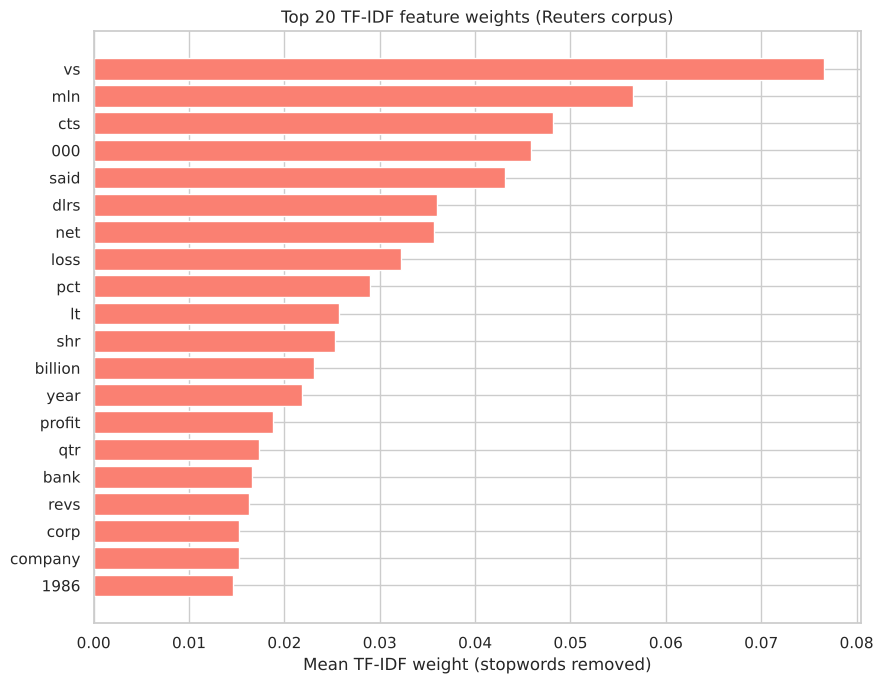

In [7]:
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = vis_tfidf_vectorizer.fit_transform(Xr_train)
feature_names_vis = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = vis_X_train_tfidf.toarray().mean(axis=0)

N = 20
top_n_idx = np.argsort(tfidf_means)[-N:]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(feature_names_vis[top_n_idx], tfidf_means[top_n_idx], color='salmon')
ax.set_xlabel('Mean TF-IDF weight (stopwords removed)')
ax.set_title(f'Top {N} TF-IDF feature weights (Reuters corpus)')
plt.tight_layout()
plt.show()

Unlike the raw-frequency ranking in section 1.3, TF-IDF's top terms tend to be more *topic-specific* vocabulary rather than generic high-frequency words — exactly the effect the IDF term is designed to produce: it discounts words that are common everywhere and rewards words that are common in some documents but rare across the whole corpus.

**Word embeddings** (Word2Vec, GloVe, or transformer-based embeddings) are a further step beyond BoW/TF-IDF: dense, low-dimensional vectors that capture semantic similarity (e.g., "king" and "queen" end up nearby). scikit-learn doesn't generate embeddings itself, but externally computed embeddings can be fed into any scikit-learn model as ordinary numeric features.

### 2.4 Hands-on checklist
1. Fit `CountVectorizer` for BoW or `TfidfVectorizer` for TF-IDF on training text only.
2. Prefer TF-IDF over raw counts when distinguishing documents by distinctive vocabulary matters more than raw frequency (most classification tasks).
3. Visualise top-weighted terms to sanity-check that the vectoriser is picking up meaningful vocabulary, not noise.

## 3. Feature Extraction from Text

Beyond single-word (unigram) counts, richer features capture more structure:

- **N-grams**: sequences of $n$ consecutive words (bigrams, trigrams, ...), capturing local word order BoW discards entirely.
- **Part-of-speech (POS) tagging**: labels each token's grammatical role (noun, verb, adjective, ...).
- **Named entity recognition (NER)**: identifies people, organisations, locations (out of scope for plain scikit-learn — typically done with spaCy).

We use the `brown` corpus (500 documents across 15 genre categories) for this section.

### 3.1 N-gram extraction

In [8]:
categories_to_use = brown.categories()[:2]
num_sents_per_category = 2
texts_b, labels_b = [], []
for i, category in enumerate(categories_to_use):
    category_sents = brown.sents(categories=category)
    for sent_tokens in category_sents[:num_sents_per_category]:
        texts_b.append(" ".join(sent_tokens))
        labels_b.append(i)

print(f"Categories used: {categories_to_use}")
for t in texts_b:
    print(f"  '{t}'")

ngram_vectorizer = CountVectorizer(ngram_range=(1, 2))
X_ngram = ngram_vectorizer.fit_transform(texts_b)
ngram_features = ngram_vectorizer.get_feature_names_out()
unigrams = [f for f in ngram_features if ' ' not in f]
bigrams = [f for f in ngram_features if ' ' in f]
print(f"\nTotal features (unigrams + bigrams): {len(ngram_features)} "
      f"({len(unigrams)} unigrams, {len(bigrams)} bigrams)")
print(f"Example bigrams: {bigrams[:8]}")

Categories used: ['adventure', 'belles_lettres']
  'Dan Morgan told himself he would forget Ann Turner .'
  'He was well rid of her .'
  'Northern liberals are the chief supporters of civil rights and of integration .'
  'They have also led the nation in the direction of a welfare state .'

Total features (unigrams + bigrams): 68 (33 unigrams, 35 bigrams)
Example bigrams: ['also led', 'and of', 'ann turner', 'are the', 'chief supporters', 'civil rights', 'dan morgan', 'direction of']


### 3.2 POS tagging

In [9]:
print("--- POS Tagging of Training Sentences ---")
all_pos_results = []
for i, text in enumerate(texts_b):
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens)
    all_pos_results.append(pos_tags)
    print(f"\nSentence {i+1}: \"{text}\"")
    print("  Tagged tokens:", " ".join(f"{tok}/{tag}" for tok, tag in pos_tags))
    if len(pos_tags) >= 2:
        tagged_bigrams = list(nltk_ngrams(pos_tags, 2))
        print("  Tagged bigrams:", ", ".join(f"{a[0]}/{a[1]}-{b[0]}/{b[1]}" for a, b in tagged_bigrams[:5]))

--- POS Tagging of Training Sentences ---



Sentence 1: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged tokens: Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged bigrams: Dan/NNP-Morgan/NNP, Morgan/NNP-told/VBD, told/VBD-himself/PRP, himself/PRP-he/PRP, he/PRP-would/MD

Sentence 2: "He was well rid of her ."
  Tagged tokens: He/PRP was/VBD well/RB rid/JJ of/IN her/PRP ./.
  Tagged bigrams: He/PRP-was/VBD, was/VBD-well/RB, well/RB-rid/JJ, rid/JJ-of/IN, of/IN-her/PRP

Sentence 3: "Northern liberals are the chief supporters of civil rights and of integration ."
  Tagged tokens: Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged bigrams: Northern/NNP-liberals/NNS, liberals/NNS-are/VBP, are/VBP-the/DT, the/DT-chief/JJ, chief/JJ-supporters/NNS

Sentence 4: "They have also led the nation in the direction of a welfare state ."
  Tagged tokens: They/PRP have/VBP also/RB led/VBN the/DT nation/NN

Common tag abbreviations: `NN`/`NNS` noun (singular/plural), `NNP`/`NNPS` proper noun, `JJ` adjective, `VB`/`VBD`/`VBG`/`VBN`/`VBP`/`VBZ` verb forms, `RB` adverb, `PRP` pronoun, `CC` coordinating conjunction, `DT` determiner, `IN` preposition/subordinator, `CD` cardinal number, `FW` foreign word. N-grams built over **(token, tag) pairs** instead of raw tokens let a model use grammatical context — e.g., distinguishing "can" as a modal verb (`MD`) from "can" as a noun (`NN`) — something plain word n-grams cannot do.

### 3.3 POS tag frequency across a larger sample

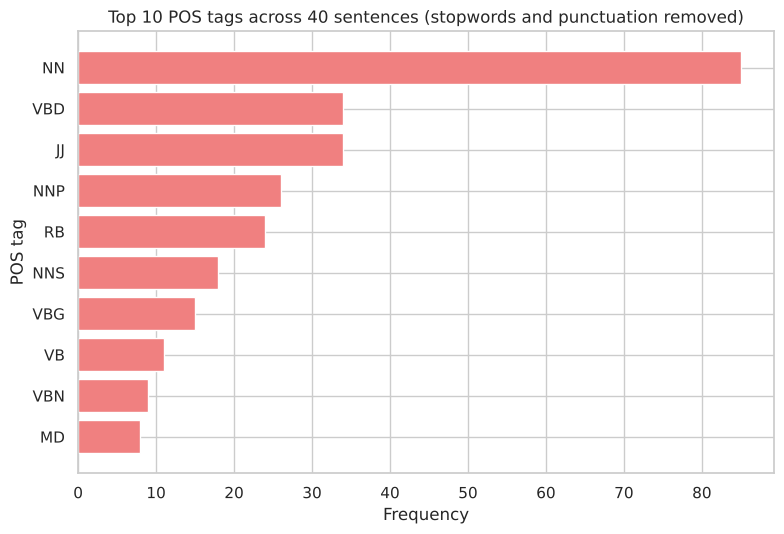

Tag frequencies: {'NN': 85, 'VBD': 34, 'JJ': 34, 'NNP': 26, 'RB': 24, 'NNS': 18, 'VBG': 15, 'VB': 11, 'VBN': 9, 'MD': 8}


In [10]:
stop_words_set = set(stopwords.words('english'))
all_tags = []
# Use a slightly larger sample than section 3.1/3.2 for a more informative frequency plot
sample_texts = [" ".join(s) for s in brown.sents(categories=categories_to_use[0])[:40]]
for text_content in sample_texts:
    tokens = nltk.word_tokenize(text_content)
    filtered = [t for t in tokens if t.lower() not in stop_words_set and t.isalpha()]
    if not filtered:
        continue
    for _, tag in nltk.pos_tag(filtered):
        all_tags.append(tag)

tag_counts = Counter(all_tags)
top_10 = tag_counts.most_common(10)
tags, counts = zip(*top_10)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(list(tags), list(counts), color='lightcoral')
ax.set_xlabel('Frequency')
ax.set_ylabel('POS tag')
ax.set_title(f'Top 10 POS tags across {len(sample_texts)} sentences (stopwords and punctuation removed)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(f"Tag frequencies: {dict(top_10)}")

Matching the book's observation, nouns (`NN`/`NNS`/`NNP`) and adjectives (`JJ`) dominate once stopwords are removed — stopword removal strips out the function words (determiners, prepositions, conjunctions) that would otherwise dominate any English text's tag distribution, leaving the content-bearing word classes visible.

### 3.4 Hands-on checklist
1. Use `CountVectorizer(ngram_range=(1, n))` to include n-grams alongside unigrams.
2. Use `nltk.pos_tag` for grammatical tagging when syntactic structure matters.
3. For full named-entity recognition, reach for a dedicated library like spaCy — scikit-learn alone doesn't provide NER.

## 4. Implementing Text Classification Models

Three classic model families, all applicable once text is vectorised: **Naive Bayes** (probabilistic, assumes conditional independence between word counts given the class — surprisingly effective for text despite the "naive" assumption), **SVM** (margin-based, Chapter 7), and **logistic regression** (Chapter 6).

We use the `brown` corpus's 15 genre categories here (first category per document as the label), as in the book.

In [11]:
document_ids = brown.fileids()
texts_full = [' '.join(brown.words(file_id)) for file_id in document_ids]
raw_labels_full = [brown.categories(file_id)[0] for file_id in document_ids]

unique_raw_labels = sorted(set(raw_labels_full))
label_to_int = {label: i for i, label in enumerate(unique_raw_labels)}
labels_full = [label_to_int[label] for label in raw_labels_full]

print(f"Brown corpus: {len(texts_full)} documents, {len(unique_raw_labels)} categories: {unique_raw_labels}")
print(f"Category counts: {Counter(raw_labels_full)}")

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    texts_full, labels_full, test_size=0.5, stratify=labels_full, random_state=2024)
print(f"\nTrain: {len(Xf_train)}, Test: {len(Xf_test)}")

Brown corpus: 500 documents, 15 categories: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']
Category counts: Counter({'learned': 80, 'belles_lettres': 75, 'lore': 48, 'news': 44, 'hobbies': 36, 'government': 30, 'fiction': 29, 'adventure': 29, 'romance': 29, 'editorial': 27, 'mystery': 24, 'reviews': 17, 'religion': 17, 'humor': 9, 'science_fiction': 6})

Train: 250, Test: 250


In [12]:
vectorizer4 = TfidfVectorizer()
Xf_train_vect = vectorizer4.fit_transform(Xf_train)
Xf_test_vect = vectorizer4.transform(Xf_test)

nb_clf = MultinomialNB().fit(Xf_train_vect, yf_train)
svm_clf = SVC(random_state=2024).fit(Xf_train_vect, yf_train)
lr_clf = LogisticRegression(random_state=2024, max_iter=1000).fit(Xf_train_vect, yf_train)

models = {'Naive Bayes': nb_clf, 'SVM': svm_clf, 'Logistic Regression': lr_clf}
model_accuracies = {}
for name, model in models.items():
    y_pred = model.predict(Xf_test_vect)
    report = classification_report(yf_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    model_accuracies[name] = report['accuracy']
    print(f"{name}: accuracy = {report['accuracy']:.4f}, "
          f"macro F1 = {report['macro avg']['f1-score']:.4f}")

Naive Bayes: accuracy = 0.2280, macro F1 = 0.0547


SVM: accuracy = 0.3320, macro F1 = 0.1601
Logistic Regression: accuracy = 0.3240, macro F1 = 0.1455


A reminder the book makes explicitly: with only 500 documents split across 15 categories (roughly 33 documents per category, and even fewer per class after the 50/50 split), these numbers are noisy estimates on a small dataset, not a benchmark result — the pattern across models matters more than the exact digits.

### 4.1 Comparing accuracy visually

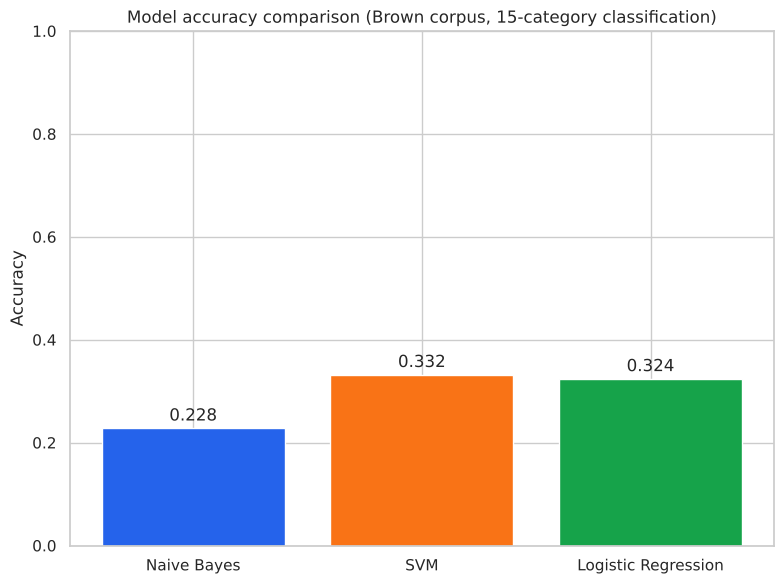

Ranking on this split: [('SVM', 0.332), ('Logistic Regression', 0.324), ('Naive Bayes', 0.228)]


In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(model_accuracies.keys(), model_accuracies.values(), color=['#2563eb', '#f97316', '#16a34a'])
ax.set_ylabel('Accuracy')
ax.set_title('Model accuracy comparison (Brown corpus, 15-category classification)')
ax.set_ylim(0, 1)
for i, (name, acc) in enumerate(model_accuracies.items()):
    ax.text(i, acc + 0.015, f'{acc:.3f}', ha='center')
plt.tight_layout()
plt.show()

ranked = sorted(model_accuracies.items(), key=lambda x: -x[1])
print("Ranking on this split:", ranked)

- **Naive Bayes** assumes word counts are conditionally independent given the class — a strong simplification, but one that works surprisingly well in high-dimensional, sparse text feature spaces.
- **SVM** looks for the maximum-margin hyperplane; in high-dimensional TF-IDF space, classes are often more linearly separable than in low dimensions (echoing Chapter 7's point about SVMs suiting wide data).
- **Logistic regression** gives calibrated, interpretable class probabilities directly.

The actual ranking above is specific to this dataset/split; on a different text classification problem (sentiment vs. topic vs. spam detection) a different model often wins, which is exactly why comparing multiple model families on a held-out set — rather than picking one by reputation — is good practice.

### 4.2 Hands-on checklist
1. Vectorize training text (TF-IDF is a strong default) and transform test text with the same fitted vectorizer.
2. Train and compare several model families — the best choice is dataset-dependent, not universal.
3. Watch dataset size relative to the number of classes — few documents per class makes any single split's accuracy a noisy estimate.

## 5. Multiclass Classification Strategies

Revisiting Chapter 6's OvR/multinomial distinction, now also introducing **one-vs-one (OvO)**: OvR trains one binary classifier per class ("class $k$ vs. everyone else"); OvO trains one binary classifier **per pair of classes** ($\binom{K}{2}$ classifiers total), and predicts by majority vote across all pairwise classifiers.

We reproduce the book's (small, illustrative) setup -- 6 Brown-corpus documents, labelled by genre, split 50/50 -- with one fix: the book's own recipe takes the corpus's first 6 file IDs, which all happen to come from the single `news` category, making a *multiclass* comparison impossible (there's only one class to classify). We instead draw 2 documents each from 3 different genres, so OvR and OvO actually have more than one class to work with.

In [14]:
categories_for_ovr_ovo = brown.categories()[:3]
file_ids_small = [fid for cat in categories_for_ovr_ovo for fid in brown.fileids(categories=cat)[:2]]
texts_small = [brown.raw(fid) for fid in file_ids_small]
labels_small = [brown.categories(fid)[0] for fid in file_ids_small]
print(f"Documents: {file_ids_small}")
print(f"Labels:    {labels_small}")

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    texts_small, labels_small, test_size=0.5, random_state=2024, stratify=labels_small)

vectorizer5 = TfidfVectorizer()
Xs_train_vect = vectorizer5.fit_transform(Xs_train)
Xs_test_vect = vectorizer5.transform(Xs_test)

ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovr_clf.fit(Xs_train_vect, ys_train)
y_pred_ovr = ovr_clf.predict(Xs_test_vect)

ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovo_clf.fit(Xs_train_vect, ys_train)
y_pred_ovo = ovo_clf.predict(Xs_test_vect)

print(f"\nTrue test labels:      {ys_test}")
print(f"OvR predicted labels:  {list(y_pred_ovr)}")
print(f"OvO predicted labels:  {list(y_pred_ovo)}")
print(f"\nOvR individual binary classifiers: {len(ovr_clf.estimators_)} "
      f"(one per class, {len(set(ys_train + ys_test))} classes seen)")
print(f"OvO individual binary classifiers: {len(ovo_clf.estimators_)} "
      f"(one per class pair)")

Documents: ['cn01', 'cn02', 'cg01', 'cg02', 'cb01', 'cb02']
Labels:    ['adventure', 'adventure', 'belles_lettres', 'belles_lettres', 'editorial', 'editorial']

True test labels:      ['belles_lettres', 'editorial', 'adventure']
OvR predicted labels:  [np.str_('belles_lettres'), np.str_('editorial'), np.str_('adventure')]
OvO predicted labels:  [np.str_('belles_lettres'), np.str_('editorial'), np.str_('adventure')]

OvR individual binary classifiers: 3 (one per class, 3 classes seen)
OvO individual binary classifiers: 3 (one per class pair)


In [15]:
report_ovr = pd.DataFrame(classification_report(ys_test, y_pred_ovr, zero_division=0, output_dict=True)).transpose()
report_ovo = pd.DataFrame(classification_report(ys_test, y_pred_ovo, zero_division=0, output_dict=True)).transpose()

print("One-vs-Rest classification report:")
print(report_ovr.round(3))
print("\nOne-vs-One classification report:")
print(report_ovo.round(3))
print(f"\nOvR accuracy: {report_ovr.loc['accuracy'].iloc[0]:.4f}")
print(f"OvO accuracy: {report_ovo.loc['accuracy'].iloc[0]:.4f}")

One-vs-Rest classification report:
                precision  recall  f1-score  support
adventure          1.0000  1.0000    1.0000   1.0000
belles_lettres     1.0000  1.0000    1.0000   1.0000
editorial          1.0000  1.0000    1.0000   1.0000
accuracy           1.0000  1.0000    1.0000   1.0000
macro avg          1.0000  1.0000    1.0000   3.0000
weighted avg       1.0000  1.0000    1.0000   3.0000

One-vs-One classification report:
                precision  recall  f1-score  support
adventure          1.0000  1.0000    1.0000   1.0000
belles_lettres     1.0000  1.0000    1.0000   1.0000
editorial          1.0000  1.0000    1.0000   1.0000
accuracy           1.0000  1.0000    1.0000   1.0000
macro avg          1.0000  1.0000    1.0000   3.0000
weighted avg       1.0000  1.0000    1.0000   3.0000

OvR accuracy: 1.0000
OvO accuracy: 1.0000


With only 3 training documents and 3 test documents (an intentionally tiny illustrative example, matching the book exactly), neither strategy has enough data to generalise meaningfully — these numbers demonstrate the **mechanics** of OvR vs. OvO (how many binary classifiers each builds, and how predictions are combined), not a reliable performance comparison. **OvR** scales linearly with the number of classes ($K$ classifiers) and is the more common default; **OvO** scales quadratically ($\binom{K}{2}$ classifiers) but each individual classifier only ever sees two classes' worth of data, which can help when classes are highly imbalanced or when a one-vs-rest split would create a very unbalanced binary subproblem.

### 5.1 Hands-on checklist
1. Use `OneVsRestClassifier(base_estimator)` or `OneVsOneClassifier(base_estimator)` to wrap any binary classifier for multiclass use.
2. Remember OvO trains $\binom{K}{2}$ models — fine for a handful of classes, potentially slow for many.
3. On very small datasets, treat single-split comparisons between strategies as illustrative, not conclusive (Chapters 6 and 8 made the same point about repeated cross-validation being the more trustworthy comparison).

## 6. Evaluating Text Models

The same precision/recall/F1/confusion-matrix toolkit from earlier chapters, applied here to the `movie_reviews` sentiment task (positive vs. negative, a binary problem).

In [16]:
documents_pairs = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents_pairs.append((list(movie_reviews.words(fileid)), category))

random.seed(2024)
random.shuffle(documents_pairs)

texts_e = [" ".join(words) for words, category in documents_pairs]
labels_e = [category for words, category in documents_pairs]

Xe_train, Xe_test, ye_train, ye_test = train_test_split(texts_e, labels_e, test_size=0.5, random_state=2024)

vectorizer6 = TfidfVectorizer()
Xe_train_vect = vectorizer6.fit_transform(Xe_train)
Xe_test_vect = vectorizer6.transform(Xe_test)

clf6 = LogisticRegression(random_state=2024, max_iter=1000)
clf6.fit(Xe_train_vect, ye_train)
y_pred_e = clf6.predict(Xe_test_vect)

print("Precision:", precision_score(ye_test, y_pred_e, average='weighted', zero_division=0))
print("Recall:   ", recall_score(ye_test, y_pred_e, average='weighted', zero_division=0))
print("F1 Score: ", f1_score(ye_test, y_pred_e, average='weighted', zero_division=0))

Precision: 0.8034174884733607
Recall:    0.803
F1 Score:  0.8029765558512367


              precision  recall  f1-score   support
neg              0.7910  0.8180    0.8040  495.0000
pos              0.8160  0.7880    0.8020  505.0000
accuracy         0.8030  0.8030    0.8030    0.8030
macro avg        0.8030  0.8030    0.8030 1000.0000
weighted avg     0.8030  0.8030    0.8030 1000.0000


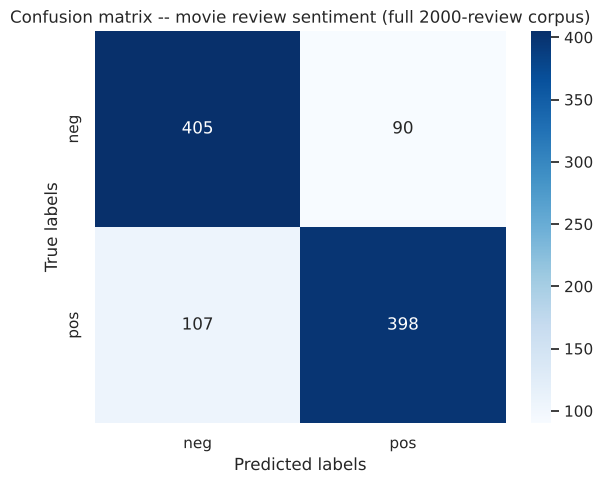

In [17]:
report_e = pd.DataFrame(classification_report(
    ye_test, y_pred_e, labels=clf6.classes_, target_names=clf6.classes_, output_dict=True, zero_division=0)).transpose()
print(report_e.round(3))

cm = confusion_matrix(ye_test, y_pred_e, labels=clf6.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf6.classes_, yticklabels=clf6.classes_, cmap='Blues', ax=ax)
ax.set_xlabel('Predicted labels')
ax.set_ylabel('True labels')
ax.set_title('Confusion matrix -- movie review sentiment (full 2000-review corpus)')
plt.tight_layout()
plt.show()

Unlike section 4's small 500-document / 15-category subset, this uses the **full** 2,000-review corpus on a simpler **binary** task (positive vs. negative), which is why accuracy here is typically both higher and a more statistically reliable estimate — more training data and fewer classes to separate.

### 6.1 Hands-on checklist
1. Train a text classifier and get both predicted labels and (if needed) probabilities.
2. Compute precision/recall/F1 — `average='weighted'` accounts for class imbalance.
3. Plot a confusion matrix to see exactly which classes get confused with which.
4. For binary text problems, ROC/AUC (Chapters 6-7) applies the same way as any other classifier.

## 7. Practical Exercises in Text Processing

### Exercise 1: Preprocessing and vectorizing text

In [18]:
sample_reviews = texts_subset[:5]
print("Sample raw review (truncated):")
print(sample_reviews[0][:300] + "...")

ex1_vectorizer = TfidfVectorizer(stop_words='english', max_features=500)
ex1_vect = ex1_vectorizer.fit_transform(sample_reviews)
print(f"\nVectorized shape: {ex1_vect.shape} (5 documents x up to 500 TF-IDF features)")
print(f"Non-zero entries per document: {ex1_vect.toarray().astype(bool).sum(axis=1)}")

Sample raw review (truncated):
at the end of an action scene in " lara croft : tomb raider , " a wall collapses near the nubile warrior . 
with her face on the floor , she gazes into the rubble , then grins abruptly and says " oh , my car keys ! " 
i mention this scene because it was the only moment in the whole damned production...

Vectorized shape: (5, 500) (5 documents x up to 500 TF-IDF features)
Non-zero entries per document: [111 147 122 135 181]


### Exercise 2: Feature extraction with n-grams

In [19]:
ex2_vectorizer = CountVectorizer(ngram_range=(1, 3), stop_words='english', max_features=30)
ex2_vect = ex2_vectorizer.fit_transform(sample_reviews)
ex2_features = ex2_vectorizer.get_feature_names_out()

n_counts = Counter(len(f.split()) for f in ex2_features)
print(f"Feature breakdown by n-gram length (top 30 by frequency): {dict(n_counts)}")
print(f"Example trigrams found: {[f for f in ex2_features if len(f.split()) == 3][:5]}")

Feature breakdown by n-gram length (top 30 by frequency): {1: 28, 2: 2}
Example trigrams found: []


### Exercise 3: Building and evaluating a multiclass classifier

Using the Brown corpus's genre categories, restricted to the 5 largest categories to keep the per-class sample size reasonable.

In [20]:
cat_counts = Counter(raw_labels_full)
top5_cats = [cat for cat, _ in cat_counts.most_common(5)]
print(f"Top 5 Brown categories by document count: {dict(cat_counts.most_common(5))}")

mask = [label in top5_cats for label in raw_labels_full]
texts_ex3 = [t for t, m in zip(texts_full, mask) if m]
labels_ex3 = [l for l, m in zip(raw_labels_full, mask) if m]

Xex3_train, Xex3_test, yex3_train, yex3_test = train_test_split(
    texts_ex3, labels_ex3, test_size=0.3, stratify=labels_ex3, random_state=2024)

vectorizer_ex3 = TfidfVectorizer()
Xex3_train_vect = vectorizer_ex3.fit_transform(Xex3_train)
Xex3_test_vect = vectorizer_ex3.transform(Xex3_test)

clf_ex3 = LogisticRegression(random_state=2024, max_iter=1000)
clf_ex3.fit(Xex3_train_vect, yex3_train)
y_pred_ex3 = clf_ex3.predict(Xex3_test_vect)

report_ex3 = pd.DataFrame(classification_report(yex3_test, y_pred_ex3, output_dict=True, zero_division=0)).transpose()
print(f"\nTrain: {len(Xex3_train)}, Test: {len(Xex3_test)}, categories: {top5_cats}")
print(report_ex3.round(3))

Top 5 Brown categories by document count: {'learned': 80, 'belles_lettres': 75, 'lore': 48, 'news': 44, 'hobbies': 36}



Train: 198, Test: 85, categories: ['learned', 'belles_lettres', 'lore', 'news', 'hobbies']
                precision  recall  f1-score  support
belles_lettres     0.5000  0.9570    0.6570  23.0000
hobbies            1.0000  0.1820    0.3080  11.0000
learned            0.5810  0.7500    0.6550  24.0000
lore               0.0000  0.0000    0.0000  14.0000
news               1.0000  0.6150    0.7620  13.0000
accuracy           0.5880  0.5880    0.5880   0.5880
macro avg          0.6160  0.5010    0.4760  85.0000
weighted avg       0.5820  0.5880    0.5190  85.0000
